In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch

# Load model and tokenizer
model_name = "codewithdark/bert-Gomotions"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

# Emotion labels (adjust based on your dataset)
emotion_labels = [
    "Admiration", "Amusement", "Anger", "Annoyance", "Approval", "Caring", "Confusion",
    "Curiosity", "Desire", "Disappointment", "Disapproval", "Disgust", "Embarrassment",
    "Excitement", "Fear", "Gratitude", "Grief", "Joy", "Love", "Nervousness", "Optimism",
    "Pride", "Realization", "Relief", "Remorse", "Sadness", "Surprise", "Neutral"
]

# Example text
text = "I'm so happy today!"
inputs = tokenizer(text, return_tensors="pt")

# Predict
with torch.no_grad():
    outputs = model(**inputs)
    probs = torch.sigmoid(outputs.logits).squeeze(0)  # Convert logits to probabilities

# Get top 5 predictions
top5_indices = torch.argsort(probs, descending=True)[:5]  # Get indices of top 5 labels
top5_labels = [emotion_labels[i] for i in top5_indices]
top5_probs = [probs[i].item() for i in top5_indices]

# Print results
print("Top 5 Predicted Emotions:")
for label, prob in zip(top5_labels, top5_probs):
    print(f"{label}: {prob:.4f}")

'''
output:
Top 5 Predicted Emotions:
Joy: 0.9478
Love: 0.7854
Optimism: 0.6342
Admiration: 0.5678
Excitement: 0.5231
'''


config.json:   0%|          | 0.00/1.90k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.22k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/712k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Top 5 Predicted Emotions:
Joy: 0.9459
Gratitude: 0.0282
Excitement: 0.0110
Admiration: 0.0097
Relief: 0.0064


'\noutput:\nTop 5 Predicted Emotions:\nJoy: 0.9478\nLove: 0.7854\nOptimism: 0.6342\nAdmiration: 0.5678\nExcitement: 0.5231\n'

README.md:   0%|          | 0.00/9.40k [00:00<?, ?B/s]

simplified/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.77MB            

simplified/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

simplified/validation-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B /  350kB            

simplified/validation-00000-of-00001.par(…): downloading bytes:           |  0.00B            

simplified/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  347kB            

simplified/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/43410 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5426 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5427 [00:00<?, ? examples/s]

AUC Score for admiration: 0.9417336506001953
AUC Score for amusement: 0.9753520093438747
AUC Score for anger: 0.9131475396535639
AUC Score for annoyance: 0.8145064372429999
AUC Score for approval: 0.8092447785119179
AUC Score for caring: 0.898339912096526
AUC Score for confusion: 0.925191034573354
AUC Score for curiosity: 0.9384696277998539
AUC Score for desire: 0.9125288579467572
AUC Score for disappointment: 0.8541238847410992
AUC Score for disapproval: 0.863269750021775
AUC Score for disgust: 0.9260276030362113
AUC Score for embarrassment: 0.8945294088151231
AUC Score for excitement: 0.9161244556614853
AUC Score for fear: 0.9632545743033685
AUC Score for gratitude: 0.9939184952978055
AUC Score for grief: 0.9461046547377483
AUC Score for joy: 0.9352980446459533
AUC Score for love: 0.9808268460592949
AUC Score for nervousness: 0.9498760982203199
AUC Score for optimism: 0.9033848091864599
AUC Score for pride: 0.8940930511920163
AUC Score for realization: 0.7546488399117367
AUC Score fo

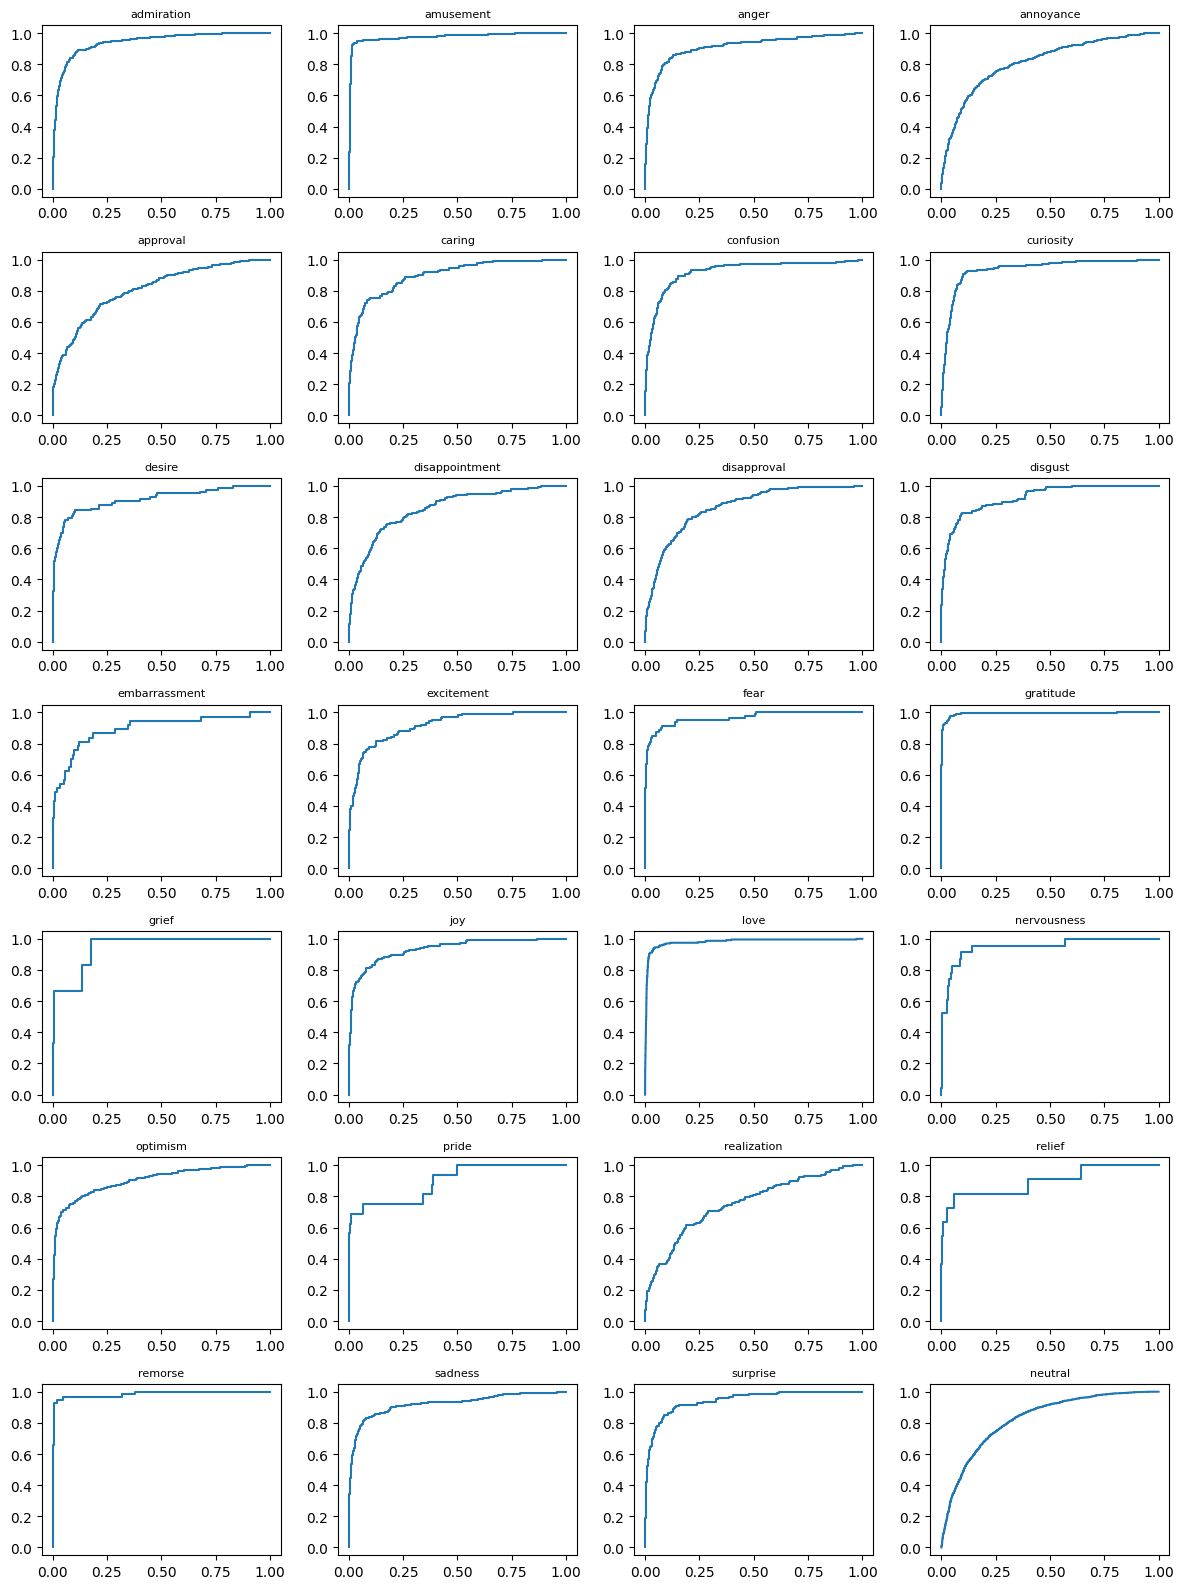

Threshold for admiration: 0.6
Corresponding F1 Score: 0.703205791106515
Threshold for amusement: 0.1
Corresponding F1 Score: 0.7894736842105263
Threshold for anger: 0.2
Corresponding F1 Score: 0.5130890052356021
Threshold for annoyance: 0.4
Corresponding F1 Score: 0.3669421487603306
Threshold for approval: 0.2
Corresponding F1 Score: 0.3630057803468208
Threshold for caring: 0.1
Corresponding F1 Score: 0.4550898203592814
Threshold for confusion: 0.1
Corresponding F1 Score: 0.4342105263157895
Threshold for curiosity: 0.1
Corresponding F1 Score: 0.5416036308623298
Threshold for desire: 0.1
Corresponding F1 Score: 0.5
Threshold for disappointment: 0.30000000000000004
Corresponding F1 Score: 0.3076923076923077
Threshold for disapproval: 0.1
Corresponding F1 Score: 0.39191290824261277
Threshold for disgust: 0.30000000000000004
Corresponding F1 Score: 0.44808743169398907
Threshold for embarrassment: 0.35
Corresponding F1 Score: 0.5373134328358209
Threshold for excitement: 0.2
Corresponding F1

In [ ]:
from datasets import load_dataset
import numpy as np
from sklearn.metrics import f1_score, roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# setting up
ds = load_dataset("google-research-datasets/go_emotions", "simplified")
k = model.config.num_labels
device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device).eval()
# emotion names in the dataset's order, used for printing
names = ds["train"].features["labels"].feature.names

# turn dataset's labels into grid
def labels(d):
    y = np.zeros((d.num_rows, k))
    for i, labs in enumerate(d["labels"]):
        y[i, labs] = 1
    return y

# BERT
def probs(texts, bs=64):
    out = []
    for i in range(0, len(texts), bs):
        b = tokenizer(texts[i:i+bs], return_tensors="pt", padding=True, truncation=True, max_length=128).to(device)
        with torch.no_grad():
            out.append(torch.sigmoid(model(**b).logits).cpu().numpy())
    return np.vstack(out)

# answer key
vy, ty = labels(ds["validation"]), labels(ds["test"])
# BERT's probabilities
vp, tp = probs(ds["validation"]["text"]), probs(ds["test"]["text"])

# roc curves and auc on test
fig, axs = plt.subplots(7, 4, figsize=(12, 16))
for i in range(k):
    fpr, tpr, _ = roc_curve(ty[:, i], tp[:, i])
    # 28 emotions fill a 7x4 grid, so row = i // 4 and column = i % 4
    axs[i // 4, i % 4].plot(fpr, tpr)
    axs[i // 4, i % 4].set_title(names[i], fontsize=8)
    print(f"AUC Score for {names[i]}: {roc_auc_score(ty[:, i], tp[:, i])}")
plt.tight_layout()
plt.show()

# cutoff per emotion (using validation)
grid = np.linspace(0.1, 0.9, 17)
th = []
for i in range(k):
    # f1 at each candidate cutoff for this emotion
    f1s = [f1_score(vy[:, i], vp[:, i] >= t) for t in grid]
    best = int(np.argmax(f1s))
    th.append(grid[best])
    print(f"Threshold for {names[i]}: {grid[best]}")
    print(f"Corresponding F1 Score: {f1s[best]}")

# f1 on test using the cutoffs from validation
f1 = []
for i in range(k):
    f1.append(f1_score(ty[:, i], tp[:, i] >= th[i]))
    print(f"F1 Scores on Test Data for {names[i]}: {f1[i]}")
# every emotion counts equally
print(f"\nMacro F1 Score: {np.mean(f1)}")